<a href="https://colab.research.google.com/github/stevenolanecon/7002LBSAI/blob/main/notebooks/week10_online_walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 online session – model building for prediction

Companion notebook to the Week 10 online recording. Run each cell as you watch: the numbers on the slides are computed here.

One dataset: Airbnb listings in Hackney, London – used for the log-target correction, model building, LASSO, and the full five-step holdout workflow.

**Before you start:**

- Go to **File → Save a copy in Drive**. Until you do this, your work only exists in this browser tab – you can't save changes back to GitHub, and closing the tab or losing the session will lose your work.
- Turn off Colab's autocomplete: **Tools → Settings → Editor → uncheck "Show context-powered code completions."** It's a setting on your own Google account, not something built into this notebook, so you'll need to do it once per account.

## Setup

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.model_selection import KFold
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
import patsy
import warnings
warnings.filterwarnings("ignore")   # M5 and M6 have a few empty type combinations; statsmodels warns but the fit is fine

air = pd.read_csv("https://raw.githubusercontent.com/stevenolanecon/7002LBSAI/main/data/airbnb_hackney.csv")
air = air.loc[:, ~air.columns.duplicated()]
air["n_accommodates2"] = air["n_accommodates"] ** 2
air["n_days_since2"] = air["n_days_since"] ** 2
amenities = [c for c in air.columns if c.startswith("d_")]
print(len(air), "Airbnb listings")

4393 Airbnb listings


## Step 1 – split before building anything

The holdout set gets carved off right here, before a single model is built. Everything else in this notebook – model building, LASSO, the bootstrap check – only ever touches `work`. `holdout` doesn't get looked at again until the very end.

In [2]:
rng = np.random.RandomState(20260921)
holdout_mask = rng.rand(len(air)) < 0.2
work, holdout = air.loc[~holdout_mask], air.loc[holdout_mask]
print(len(work), "in the work set;", len(holdout), "in the holdout set")

3528 in the work set; 865 in the holdout set


## Part 1 – six models, built up by hand

Price is per night, in pounds (the textbook labels it dollars, but the listings are in pounds). Each model adds to the one before. M6 adds all 50 amenity dummies. All six are fit on `work` only.

In [3]:
formulas = {
    "M1": "price ~ n_accommodates",
    "M2": "price ~ n_accommodates + n_beds + C(f_room_type) + C(f_property_type)",
    "M3": "price ~ n_accommodates + n_beds + C(f_room_type) + C(f_property_type)"
          " + n_bathrooms + C(f_cancellation_policy) + C(f_bed_type)",
    "M4": "price ~ n_accommodates + n_accommodates2 + n_beds + C(f_room_type) + C(f_property_type)"
          " + n_bathrooms + C(f_cancellation_policy) + C(f_bed_type) + n_days_since + n_days_since2",
    "M5": "price ~ n_accommodates + n_accommodates2 + n_beds + C(f_room_type)*C(f_property_type)"
          " + n_bathrooms + C(f_cancellation_policy) + C(f_bed_type) + n_days_since + n_days_since2",
}
formulas["M6"] = formulas["M5"] + " + " + " + ".join(amenities)

Fit each model on the whole work set (training RMSE and BIC), then run 5-fold cross-validation **within the work set** with the same folds for every model.

In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=20260921)
cv = {name: [] for name in formulas}
for tr, te in kf.split(work):
    train, test = work.iloc[tr], work.iloc[te]
    for name, f in formulas.items():
        pred = smf.ols(f, data=train).fit().predict(test)
        cv[name].append(np.sqrt(np.mean((test["price"] - pred) ** 2)))

rows = []
for name, f in formulas.items():
    m = smf.ols(f, data=work).fit()
    rows.append({"Model": name, "N coef": len(m.params), "R2": round(m.rsquared, 2),
                 "Training RMSE": round(np.sqrt(np.mean(m.resid ** 2)), 1),
                 "CV RMSE": round(np.mean(cv[name]), 1), "BIC": round(m.bic)})
pd.DataFrame(rows)

,Model,N coef,R2,Training RMSE,CV RMSE,BIC
0,M1,2,0.38,42.7,42.4,36523
1,M2,6,0.45,40.4,40.0,36157
2,M3,10,0.47,39.6,39.2,36049
3,M4,13,0.48,39.4,39.1,36038
4,M5,15,0.48,39.3,39.0,36043
5,M6,65,0.52,37.9,38.1,36184


Both RMSEs keep falling to M6, but BIC is lowest at M4: it penalises M6's 65 coefficients.

## Part 2 – LASSO

LASSO needs every variable on the same scale, so we standardise first. `patsy.dmatrices` turns the M6 formula into the same columns OLS used (dummies, interactions and all). `LassoCV` picks λ (called `alpha` in scikit-learn) by 5-fold cross-validation – **inside** the work set it's given. This is already the final fit: nothing about it needs re-estimating later.

In [5]:
y, X = patsy.dmatrices(formulas["M6"], data=work, return_type="dataframe")
y = y.values.ravel()
X = X.drop(columns=["Intercept"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lasso = LassoCV(cv=5, random_state=20260921, max_iter=20000).fit(X_scaled, y)
print("lambda chosen:", round(lasso.alpha_, 3))
print("coefficients kept:", (lasso.coef_ != 0).sum(), "of", len(lasso.coef_))
print("in-sample RMSE:", round(np.sqrt(np.mean((y - lasso.predict(X_scaled)) ** 2)), 1))

lambda chosen: 0.479
coefficients kept: 36 of 64
in-sample RMSE: 38.0


To compare LASSO with M6 fairly, cross-validate the whole LASSO procedure, choice of λ included, on the same kind of folds, still within the work set.

In [6]:
lasso_cv = []
for tr, te in KFold(n_splits=5, shuffle=True, random_state=20260921).split(X_scaled):
    lm = LassoCV(cv=5, random_state=20260921, max_iter=20000).fit(X_scaled[tr], y[tr])
    lasso_cv.append(np.sqrt(np.mean((y[te] - lm.predict(X_scaled[te])) ** 2)))
print("LASSO cross-validated RMSE:", round(np.mean(lasso_cv), 1))
print("M6 OLS cross-validated RMSE:", round(np.mean(cv["M6"]), 1))

LASSO cross-validated RMSE: 38.0
M6 OLS cross-validated RMSE: 38.1


### What survived

The ten largest coefficients LASSO kept. Because the variables are standardised, each is the change in price (£ per night) for a one standard deviation change in that variable.

In [7]:
coefs = pd.Series(lasso.coef_, index=X.columns)
kept = coefs[coefs != 0]
top10 = kept.reindex(kept.abs().sort_values(ascending=False).index).head(10)
top10.round(2)

C(f_room_type)[T.Private room]                               -18.99
n_accommodates2                                               18.01
n_bathrooms                                                    7.13
d_washerdryer                                                  3.61
C(f_room_type)[T.Shared room]                                 -3.00
d_tv                                                           2.85
d_elevatorinbuilding                                           2.51
d_dryer                                                        2.47
d_petsallowed                                                  2.20
C(f_room_type)[T.Private room]:C(f_property_type)[T.House]    -2.03
dtype: float64

### Why classical inference fails after LASSO – made visible

There are no standard errors or p-values here, and that's not an oversight. Which variables survive is decided by this same data LASSO is then estimated on, so classical formulas – built on the assumption the model was fixed *before* any data arrived – don't apply. This is **post-selection inference**, and refitting plain OLS on just the survivors doesn't fix it either, since the list going in was still chosen by looking at this data first.

Here's the selection step made concrete: refit LASSO on 30 different bootstrap resamples of the same work set, and track how often each of the top 10 variables above actually survives.

In [8]:
n_boot = 30
boot_rng = np.random.RandomState(7)
sel_counts = np.zeros(X_scaled.shape[1])
for b in range(n_boot):
    idx = boot_rng.choice(len(y), size=len(y), replace=True)
    lb = LassoCV(cv=5, random_state=b, max_iter=20000).fit(X_scaled[idx], y[idx])
    sel_counts += (lb.coef_ != 0)
sel_freq = pd.Series(sel_counts, index=X.columns)

print("Always selected (30/30):", int((sel_freq == n_boot).sum()), "of", len(sel_freq), "candidates")
print("Selected at least once:  ", int((sel_freq > 0).sum()), "of", len(sel_freq), "candidates")
sel_freq.reindex(top10.index).astype(int)

Always selected (30/30): 15 of 64 candidates
Selected at least once:   64 of 64 candidates


C(f_room_type)[T.Private room]                                30
n_accommodates2                                               30
n_bathrooms                                                   30
d_washerdryer                                                 29
C(f_room_type)[T.Shared room]                                 30
d_tv                                                          30
d_elevatorinbuilding                                          30
d_dryer                                                       30
d_petsallowed                                                 30
C(f_room_type)[T.Private room]:C(f_property_type)[T.House]    28
dtype: int64

If selection were deterministic, every row above would read 30. It isn't – which is exactly the point: the model itself is a random outcome of this sample, not something decided independently of it.

## Step 3 – choosing the winner

Step 3 isn't the same action for every method. For **LASSO**, nothing is left to do: `LassoCV` above was already fit on the whole work set, not a fold – the internal CV only ever chose λ. For the **hand-built route**, it's a real step: the M1–M6 comparison above fit each model on 80%-sized training folds, so whichever one wins needs refitting on the *entire* work set before it's a finished model.

Model selection among M1–M6 didn't hand us one clear winner – M6 wins on CV RMSE, M4 wins on BIC by a wide margin. This notebook's call, matching the slides: **M6**, because the goal here is predicting price as accurately as possible. A project valuing a simpler model would reasonably pick M4 instead, and should say so explicitly.

In [9]:
m6_work = smf.ols(formulas["M6"], data=work).fit()
print("M6 re-estimated on the whole work set:", len(m6_work.params), "coefficients")

M6 re-estimated on the whole work set: 65 coefficients


## Steps 4 and 5 – apply both to the holdout set, and evaluate

Two finalists go forward: **M6**, re-estimated in step 3, and **LASSO**, which never needed step 3 at all. `holdout` has sat untouched since the very first cell in this section – this is the first time either model sees it.

In [10]:
holdout_pred = m6_work.predict(holdout)
holdout_rmse = np.sqrt(np.mean((holdout["price"] - holdout_pred) ** 2))

Xh = patsy.dmatrix(formulas["M6"].split("~")[1], data=holdout, return_type="dataframe")
Xh = Xh.drop(columns=["Intercept"]).reindex(columns=X.columns, fill_value=0)
lasso_holdout_pred = lasso.predict(scaler.transform(Xh))
lasso_holdout_rmse = np.sqrt(np.mean((holdout["price"].values - lasso_holdout_pred) ** 2))

pd.DataFrame({
    "Model": ["M6", "LASSO"],
    "Holdout RMSE": [round(holdout_rmse, 2), round(lasso_holdout_rmse, 2)],
    "Work-set CV RMSE": [round(np.mean(cv["M6"]), 1), round(np.mean(lasso_cv), 1)],
})

,Model,Holdout RMSE,Work-set CV RMSE
0,M6,31.40,38.1
1,LASSO,31.32,38.0


A near dead heat on data neither model ever touched, with LASSO using little more than half the coefficients. That's the same claim from Part 2 – "matches M6's fit, with fewer moving parts" – checked again, honestly, on data that had no say in choosing either model.

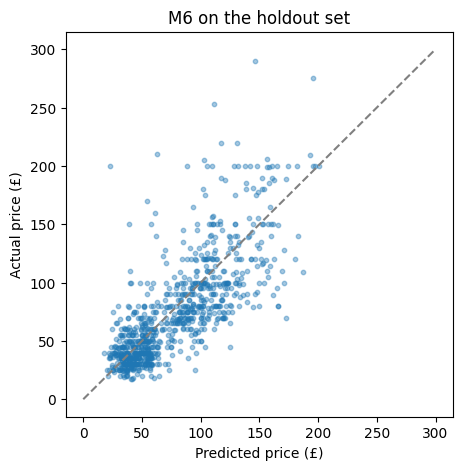

In [11]:
import matplotlib.pyplot as plt
keep = (holdout["price"] < 300) & (holdout_pred < 300)
plt.figure(figsize=(5, 5))
plt.scatter(holdout_pred[keep], holdout["price"][keep], alpha=0.4, s=10)
plt.plot([0, 300], [0, 300], "--", color="grey")
plt.xlabel("Predicted price (£)")
plt.ylabel("Actual price (£)")
plt.title("M6 on the holdout set")
plt.show()

Points above the dashed line were underpredicted. The model struggles most with the expensive listings.